<a href="https://colab.research.google.com/github/4fnfphchgp-source/ipd/blob/main/%D0%9A%D0%BE%D0%BB%D1%87%D0%B0%D0%BD%D0%BE%D0%B2%D0%B0_%D0%94%D0%B0%D1%80%D1%8C%D1%8F_%D0%9126_222_%D0%BF%D0%B0%D0%BD%D0%B4%D0%B0%D1%81.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

with zipfile.ZipFile('/archive.zip', 'r') as z:
    with z.open('household_power_consumption.txt') as f:
        df = pd.read_csv(f, sep=';', na_values=['?'], low_memory=False)

df['Datetime'] = pd.to_datetime(
    df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M:%S'
)
df = df.set_index('Datetime').sort_index()

df['hour'] = df.index.hour
df['is_weekend'] = df.index.dayofweek >= 5
df['date'] = df.index.date
season_map = {
    12: 'Зима', 1: 'Зима', 2: 'Зима',
    3: 'Весна', 4: 'Весна', 5: 'Весна',
    6: 'Лето', 7: 'Лето', 8: 'Лето',
    9: 'Осень', 10: 'Осень', 11: 'Осень'
}
df['season'] = df.index.month.map(season_map)

base_profile = df.groupby('hour')['Global_active_power'].mean()
wd_profile = df.groupby(['is_weekend', 'hour'])['Global_active_power'].mean().unstack(0)
wd_profile.columns = ['Будни', 'Выходные']
season_profile = df.groupby(['season', 'hour'])['Global_active_power'].mean().unstack(0)[['Зима', 'Весна', 'Лето', 'Осень']]

day_counts = df.groupby('date')['Global_active_power'].count()
complete_dates = day_counts[day_counts == 1440].index
q1, q3 = df['Global_active_power'].quantile([0.25, 0.75])
iqr_upper = q3 + 1.5 * (q3 - q1)

methods = {
    'Базовый (dropna, mean)': base_profile,
    'Только полные сутки': df[df['date'].isin(complete_dates)].groupby('hour')['Global_active_power'].mean(),
    'Интерполяция (linear)': df['Global_active_power'].interpolate('linear').groupby(df['hour']).mean(),
    'Заполнение нулями': df['Global_active_power'].fillna(0).groupby(df['hour']).mean(),
    'Без выбросов (IQR)': df[df['Global_active_power'] <= iqr_upper].groupby('hour')['Global_active_power'].mean(),
    'Медиана': df.groupby('hour')['Global_active_power'].median(),
}

report = []
for name, series in methods.items():
    diff = series - base_profile
    report.append({
        'Метод': name,
        'Среднее (кВт)': series.mean(),
        'Сдвиг (%)': (series.mean() - base_profile.mean()) / base_profile.mean() * 100,
        'MAE (кВт)': diff.abs().mean(),
        'MAPE (%)': (diff.abs() / base_profile).mean() * 100
    })

print("=== Сравнение способов обработки ===")
display(pd.DataFrame(report).round(3))

=== Сравнение способов обработки ===


,Метод,Среднее (кВт),Сдвиг (%),MAE (кВт),MAPE (%)
0,"Базовый (dropna, mean)",1.091,0.000,0.000,0.000
1,Только полные сутки,1.082,-0.834,0.009,0.876
2,Интерполяция (linear),1.090,-0.113,0.005,0.532
3,Заполнение нулями,1.078,-1.243,0.014,1.252
4,Без выбросов (IQR),0.947,-13.220,0.144,11.249
5,Медиана,0.879,-19.466,0.232,25.703


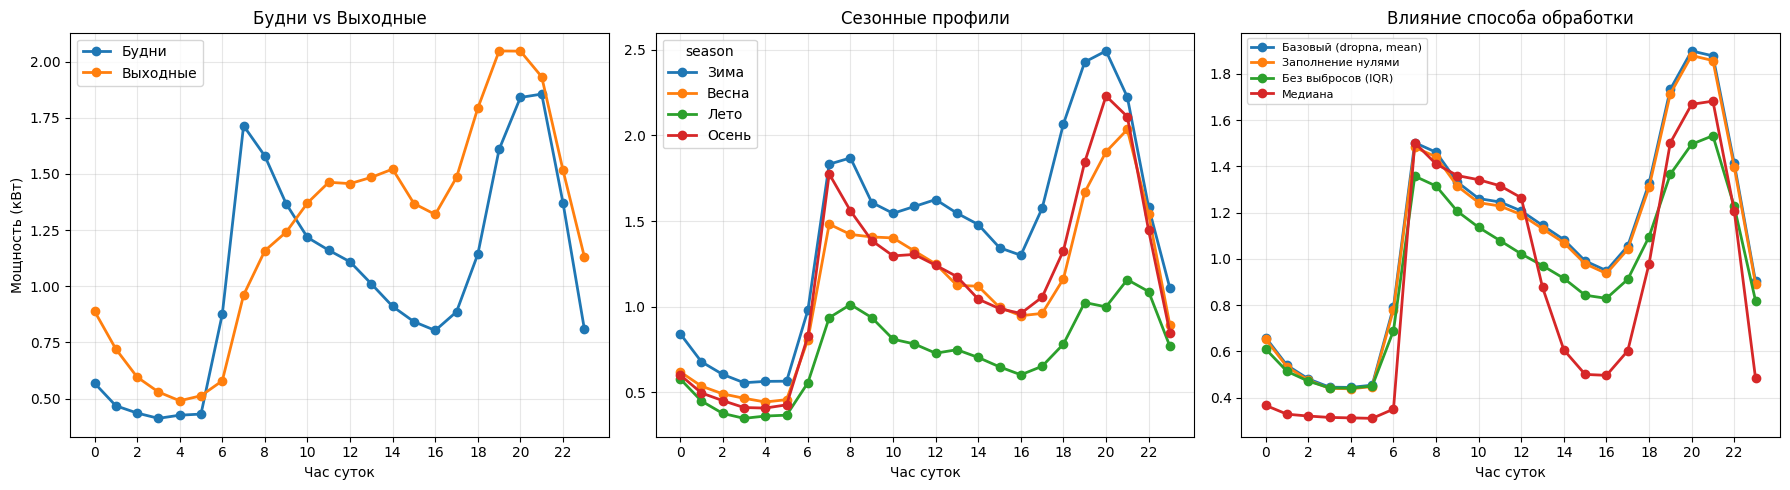

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

wd_profile.plot(ax=axes[0], marker='o', linewidth=2)
axes[0].set_title('Будни vs Выходные')
axes[0].set_xlabel('Час суток')
axes[0].set_ylabel('Мощность (кВт)')
axes[0].set_xticks(range(0, 24, 2))
axes[0].grid(True, alpha=0.3)

season_profile.plot(ax=axes[1], marker='o', linewidth=2)
axes[1].set_title('Сезонные профили')
axes[1].set_xlabel('Час суток')
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(True, alpha=0.3)

for name in ['Базовый (dropna, mean)', 'Заполнение нулями', 'Без выбросов (IQR)', 'Медиана']:
    axes[2].plot(methods[name].index, methods[name].values, marker='o', linewidth=2, label=name)
axes[2].set_title('Влияние способа обработки')
axes[2].set_xlabel('Час суток')
axes[2].set_xticks(range(0, 24, 2))
axes[2].legend(fontsize=8)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('energy_profiles.png', dpi=150)
plt.show()